# M4 · Set sintético de imágenes

## 1. Clonar repositorio

In [1]:
# Rama que contiene M4/eval_visual (debe estar subida a GitHub)
RAMA = "LuisM4"

!git clone --branch {RAMA} --single-branch https://github.com/luisNP21/Topicos-IA.git /content/repo

Cloning into '/content/repo'...
remote: Enumerating objects: 1419, done.
remote: Counting objects: 100% (466/466), done.
remote: Compressing objects: 100% (376/376), done.
remote: Total 1419 (delta 166), reused 311 (delta 84), pack-reused 953 (from 2)
Receiving objects: 100% (1419/1419), 27.96 MiB | 19.29 MiB/s, done.
Resolving deltas: 100% (582/582), done.


In [2]:
%cd /content/repo
!git pull
%cd M4/eval_visual
%ls

/content/repo
Already up to date.
/content/repo/M4/eval_visual
config.yaml       generar_set.py  README.md         start_eval_visual.ipynb
degradaciones.py  manuscrito.py   render.py         utilidades.py
fonts/            marcas.py       requirements.txt  visibilidad.py


## 2. Instalar dependencias

In [3]:
!pip install -r requirements.txt -q

## 3. Montar Drive y definir `PROJECT_ROOT`

Las imágenes se guardan en `<PROJECT_ROOT>/M4/data/imagenes/` (fuera de git). El gold set se lee del repo clonado.

In [4]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/TopicosIA/Proyecto-Salud")
PROJECT_ROOT.mkdir(parents=True, exist_ok=True)

# .env en la raiz del repo: load_dotenv() lo encuentra al subir desde M4/eval_visual
with open("/content/repo/.env", "w") as f:
    f.write(f"PROJECT_ROOT={PROJECT_ROOT}\n")
print(".env generado (no versionado, solo vive en este runtime)")

Mounted at /content/drive
.env generado (no versionado, solo vive en este runtime)


## 4. Revisar con una muestra

Genera solo 3 documentos para comprobar que todo funciona antes de la corrida completa.

In [5]:
!python generar_set.py --limite 3

[01:45:58] Eval set de M3 cargado: 15 casos (eval_set_casos.json)
[01:46:00] Fuente impresa: /usr/local/lib/python3.13/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf | caligrafias: 16
[01:46:00] Documentos: 3 | niveles: 28 | barrido: 3 docs | procesos: 11
[01:46:43]   3/3 documentos | 84 imagenes | 43 s
[01:47:09] Listo: 84 imagenes en /content/drive/MyDrive/TopicosIA/Proyecto-Salud/M4/data/imagenes (69 s)
[01:47:09] Manifiesto: /content/drive/MyDrive/TopicosIA/Proyecto-Salud/M4/data/imagenes/manifest.json
[01:47:09] Casos por nivel: /content/drive/MyDrive/TopicosIA/Proyecto-Salud/M4/data/imagenes/casos
{'n_documentos': 3, 'n_imagenes': 84, 'imagenes_dir': '/content/drive/MyDrive/TopicosIA/Proyecto-Salud/M4/data/imagenes', 'manifest_path': '/content/drive/MyDrive/TopicosIA/Proyecto-Salud/M4/data/imagenes/manifest.json', 'casos_dir': '/content/drive/MyDrive/TopicosIA/Proyecto-Salud/M4/data/imagenes/casos'}


## 5. Generar el set completo

28 niveles: 3 base con los 59 documentos (`limpio`, `foto_realista`, `manuscrito_foto`) y 25 barridos de severidad sobre un subconjunto fijo de 20 documentos. Ver el README para las cifras y el tiempo medidos.

Para generar solo algunos niveles: `!python generar_set.py --niveles limpio foto_realista manuscrito_foto`

In [6]:
!python generar_set.py

[01:47:09] Eval set de M3 cargado: 15 casos (eval_set_casos.json)
[01:47:09] Fuente impresa: /usr/local/lib/python3.13/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf | caligrafias: 16
[01:47:09] Documentos: 15 | niveles: 28 | barrido: 15 docs | procesos: 11
[01:48:03]   5/15 documentos | 140 imagenes | 54 s
[01:48:04]   10/15 documentos | 280 imagenes | 55 s
[01:48:39]   15/15 documentos | 420 imagenes | 90 s
[01:48:40] Listo: 420 imagenes en /content/drive/MyDrive/TopicosIA/Proyecto-Salud/M4/data/imagenes (90 s)
[01:48:40] Manifiesto: /content/drive/MyDrive/TopicosIA/Proyecto-Salud/M4/data/imagenes/manifest.json
[01:48:40] Casos por nivel: /content/drive/MyDrive/TopicosIA/Proyecto-Salud/M4/data/imagenes/casos
{'n_documentos': 15, 'n_imagenes': 420, 'imagenes_dir': '/content/drive/MyDrive/TopicosIA/Proyecto-Salud/M4/data/imagenes', 'manifest_path': '/content/drive/MyDrive/TopicosIA/Proyecto-Salud/M4/data/imagenes/manifest.json', 'casos_dir': '/content/drive/MyDrive/TopicosI

## 6. Verificar el resultado

Documentos: 15 | Imagenes: 420
nivel                        docs  pags  %palabras_ocultas  entidades no visibles
limpio                         15    15         0.00      0 de 15
foto_realista                  15    15         0.28      0 de 15
manuscrito_foto                15    15         0.00      0 de 15
manuscrito_leve                15    15         0.00      0 de 15
manuscrito_moderado            15    15         0.00      0 de 15
manuscrito_severo              15    15         0.00      0 de 15
sombra_leve                    15    15         0.00      0 de 15
sombra_moderado                15    15         0.00      0 de 15
sombra_severo                  15    15        18.57      2 de 15
flash_leve                     15    15         0.00      0 de 15
flash_moderado                 15    15         0.00      0 de 15
flash_severo                   15    15         0.00      0 de 15
perspectiva_leve               15    15         0.00      0 de 15
perspectiva_moderado         

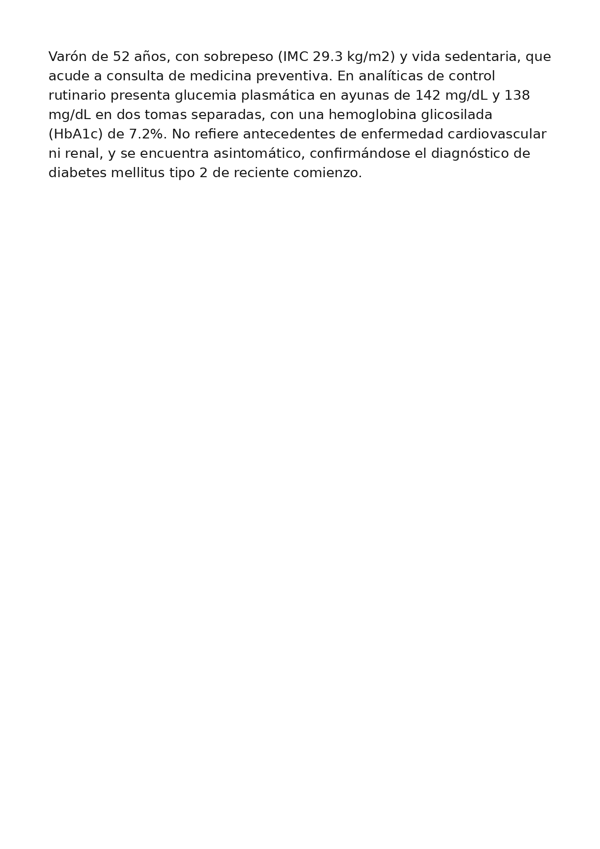

foto_realista | paginas: 1 | efectos: ['firma', 'deformacion_papel', 'perspectiva', 'tinte', 'ruido']


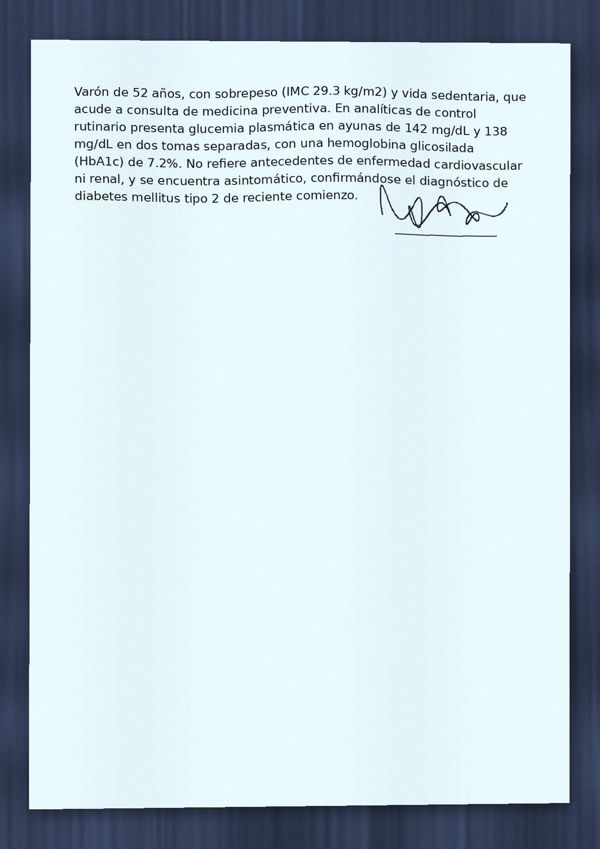

manuscrito_foto | paginas: 1 | efectos: ['notas_margen', 'deformacion_papel', 'perspectiva', 'sombra_dura', 'tinte', 'ruido']


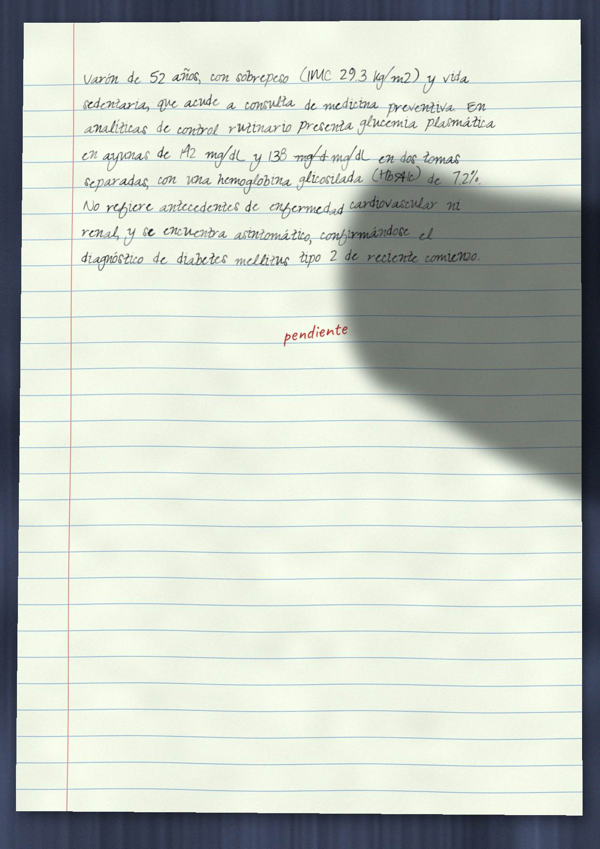

manuscrito_leve | paginas: 1 | efectos: []


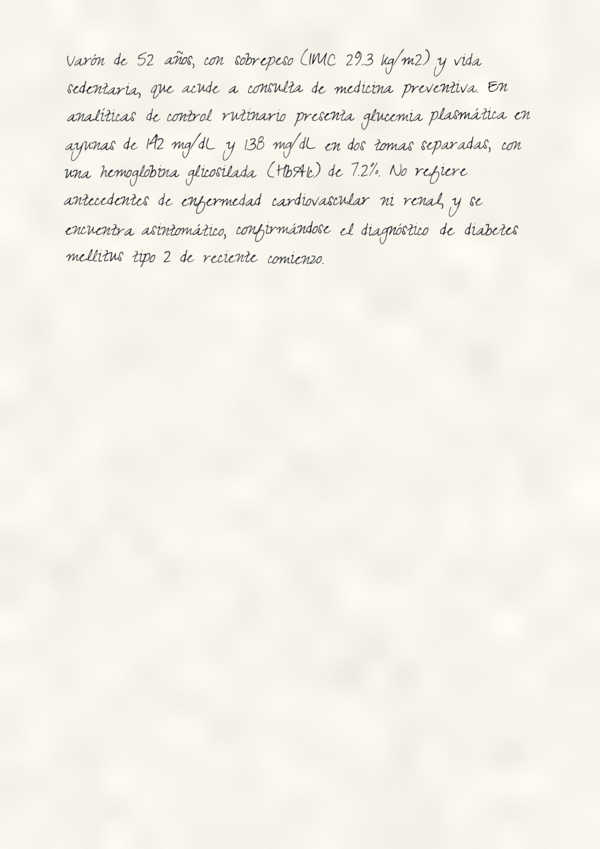

manuscrito_moderado | paginas: 1 | efectos: []


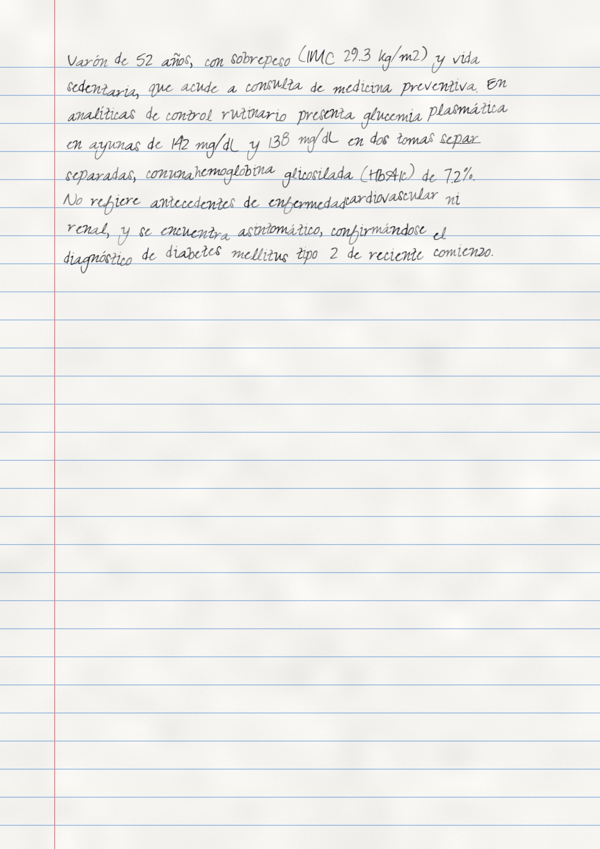

manuscrito_severo | paginas: 1 | efectos: []


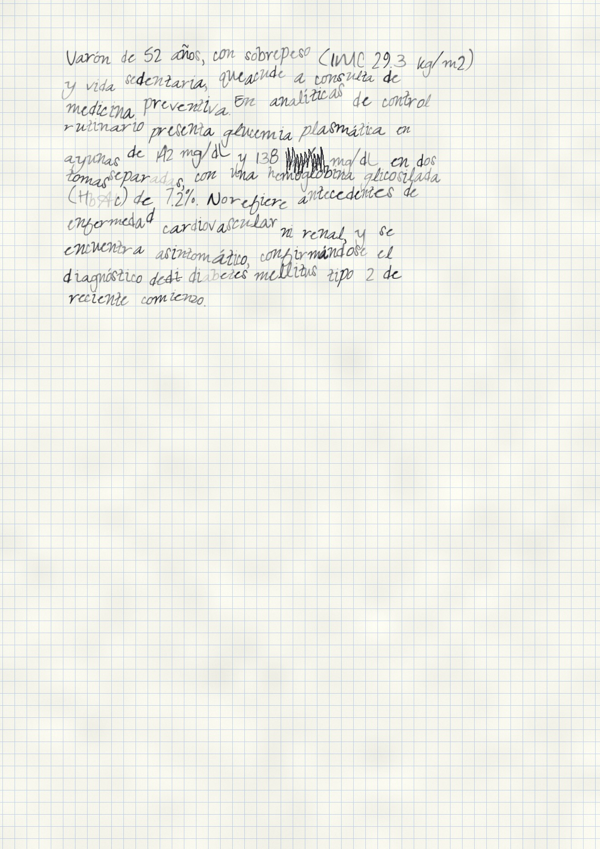

sombra_leve | paginas: 1 | efectos: ['sombra_dura']


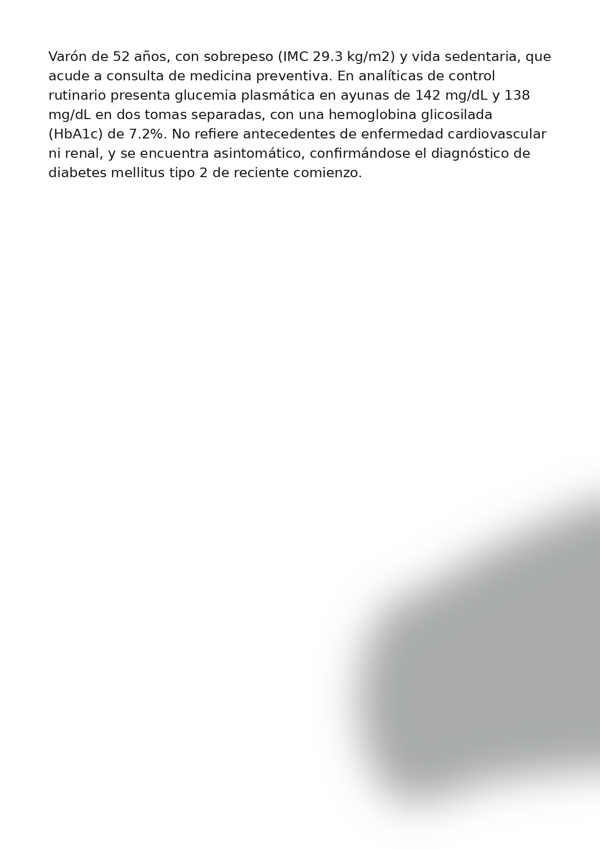

sombra_moderado | paginas: 1 | efectos: ['sombra_dura']


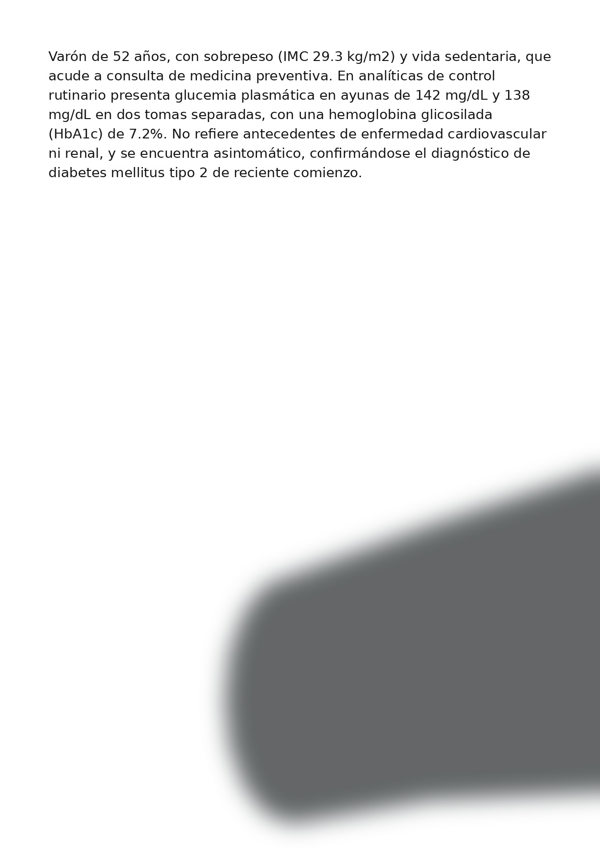

sombra_severo | paginas: 1 | efectos: ['sombra_dura']


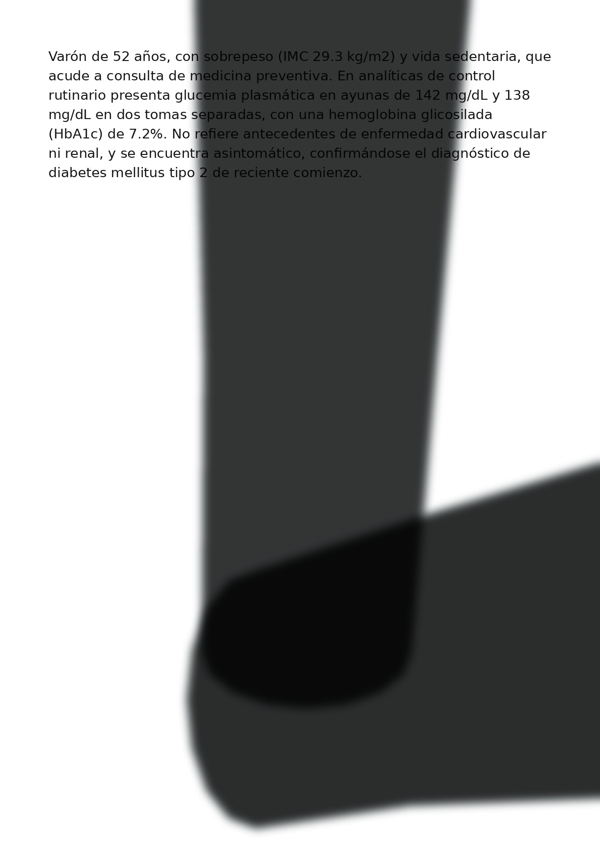

flash_leve | paginas: 1 | efectos: ['flash']


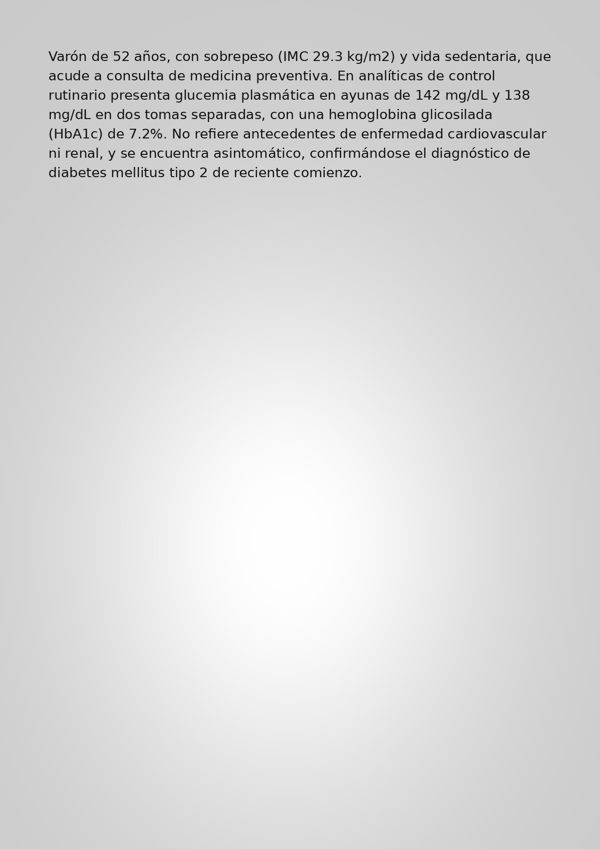

flash_moderado | paginas: 1 | efectos: ['flash']


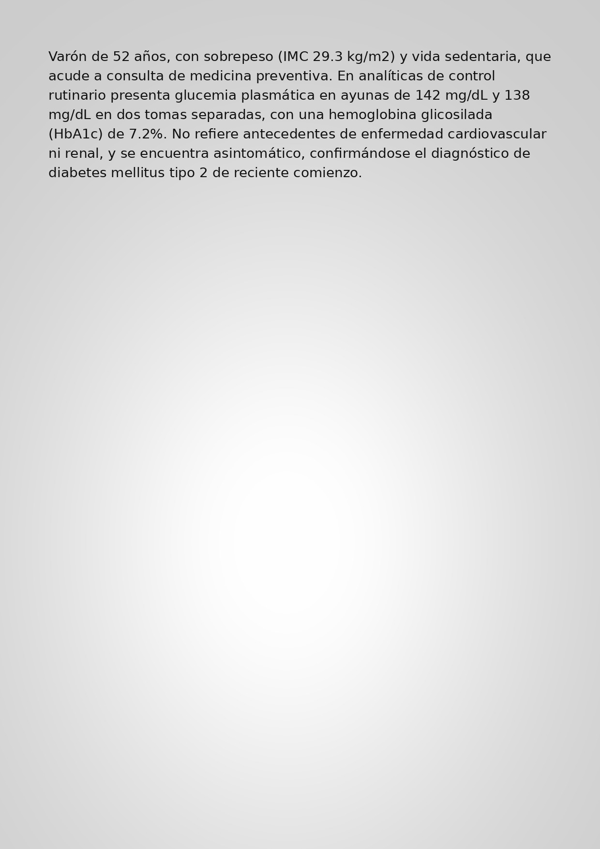

flash_severo | paginas: 1 | efectos: ['flash']


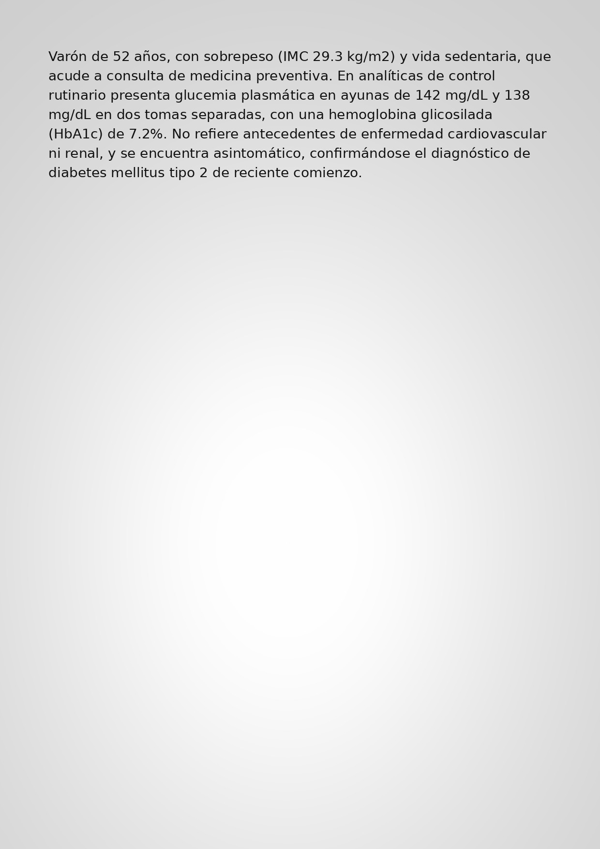

perspectiva_leve | paginas: 1 | efectos: ['deformacion_papel', 'perspectiva']


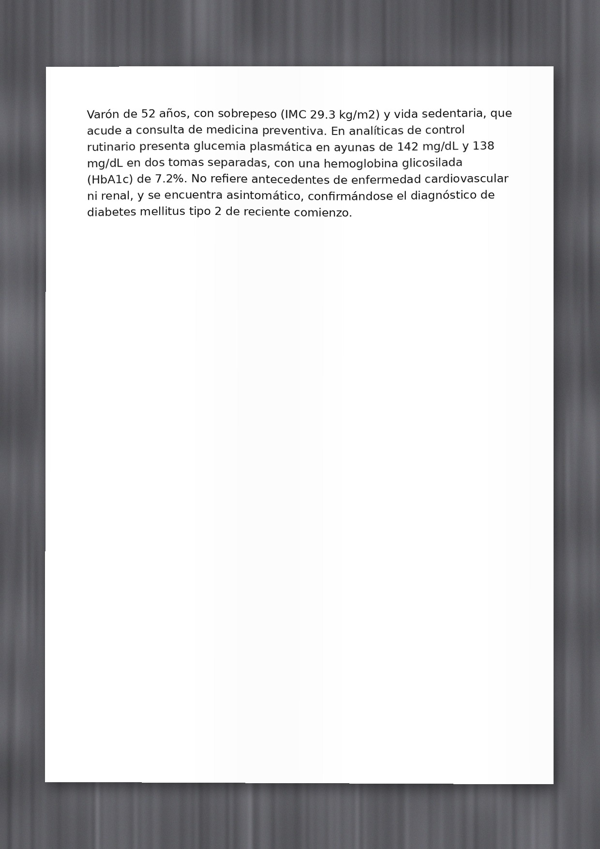

perspectiva_moderado | paginas: 1 | efectos: ['deformacion_papel', 'perspectiva']


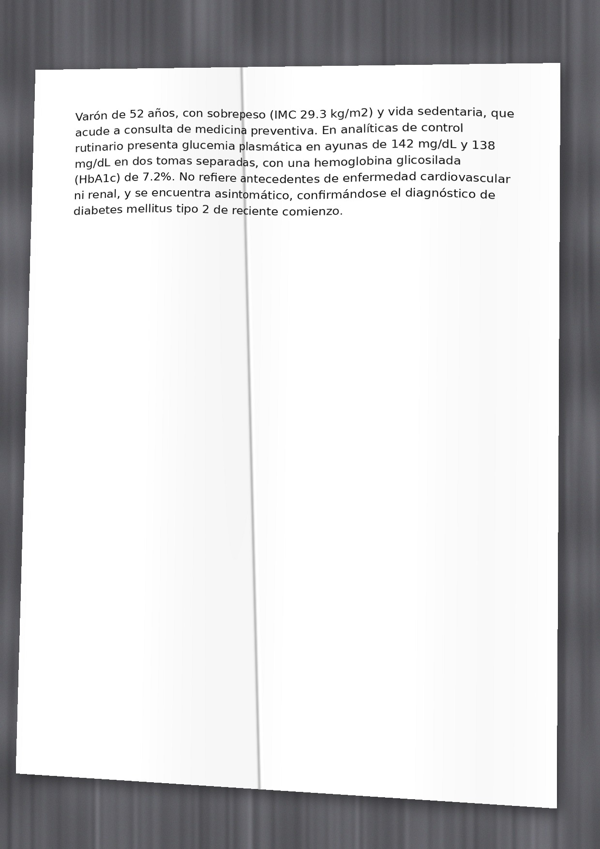

perspectiva_severo | paginas: 1 | efectos: ['deformacion_papel', 'perspectiva']


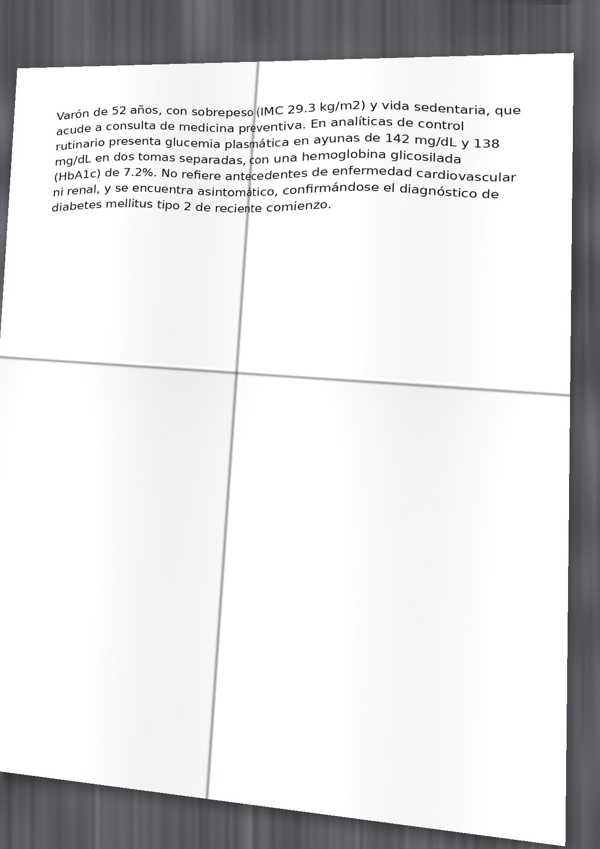

desenfoque_leve | paginas: 1 | efectos: ['desenfoque']


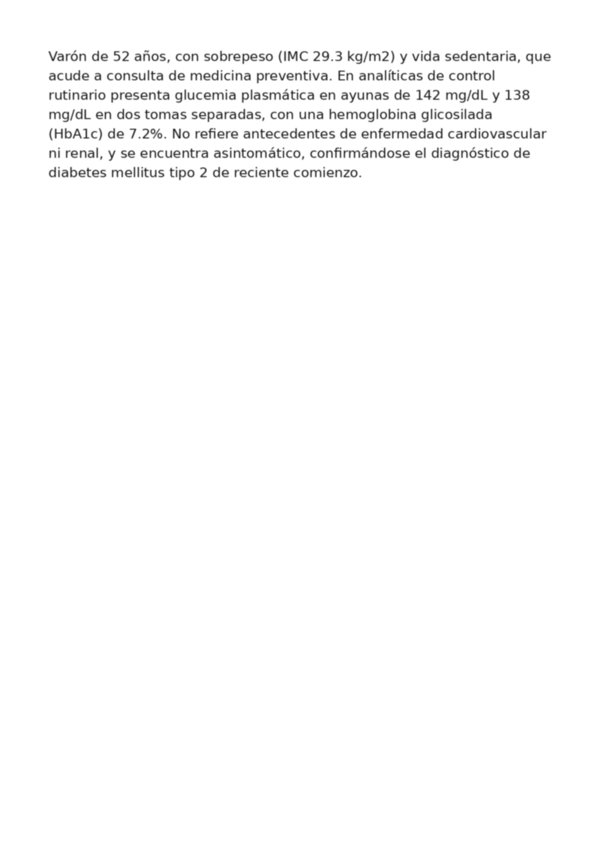

desenfoque_moderado | paginas: 1 | efectos: ['desenfoque', 'desenfoque_parcial']


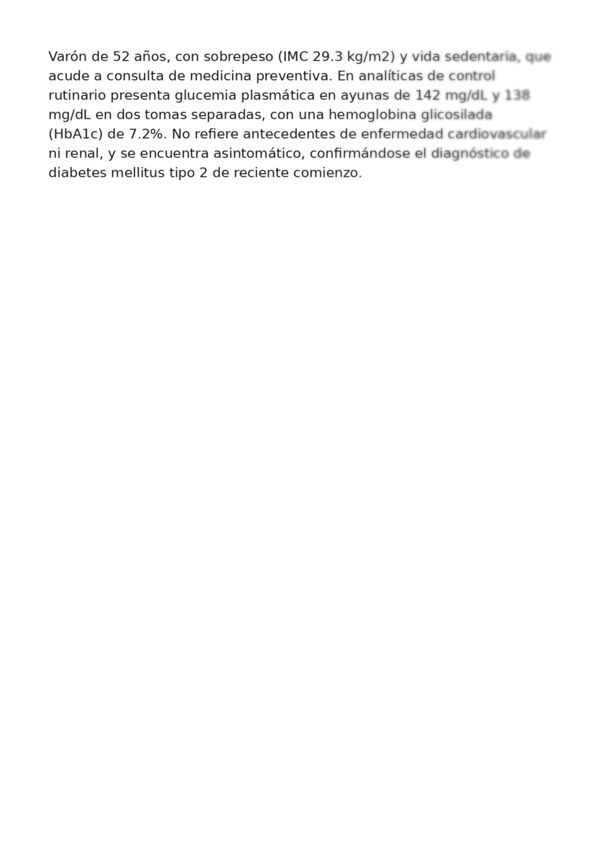

desenfoque_severo | paginas: 1 | efectos: ['movimiento', 'desenfoque_parcial']


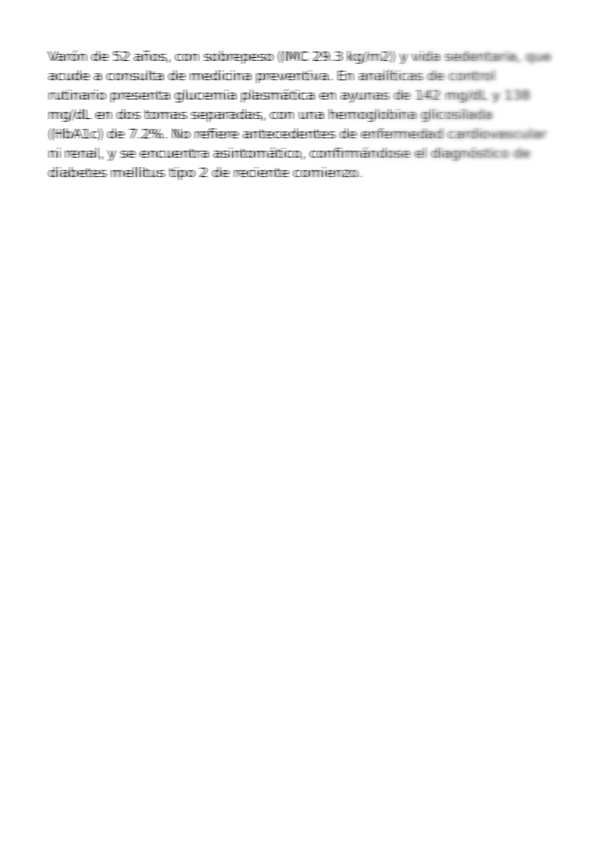

rotacion_recorte_leve | paginas: 1 | efectos: ['rotacion']


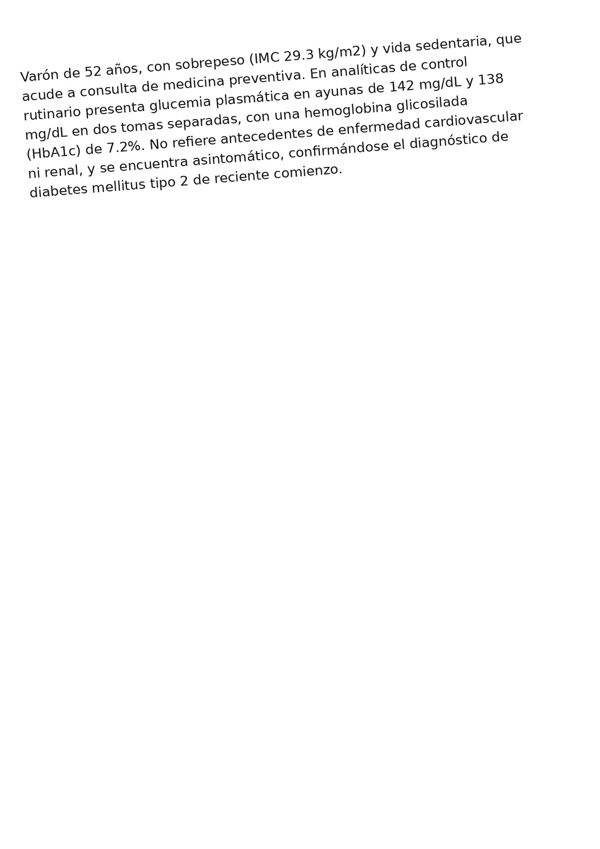

rotacion_recorte_moderado | paginas: 1 | efectos: ['rotacion', 'recorte']


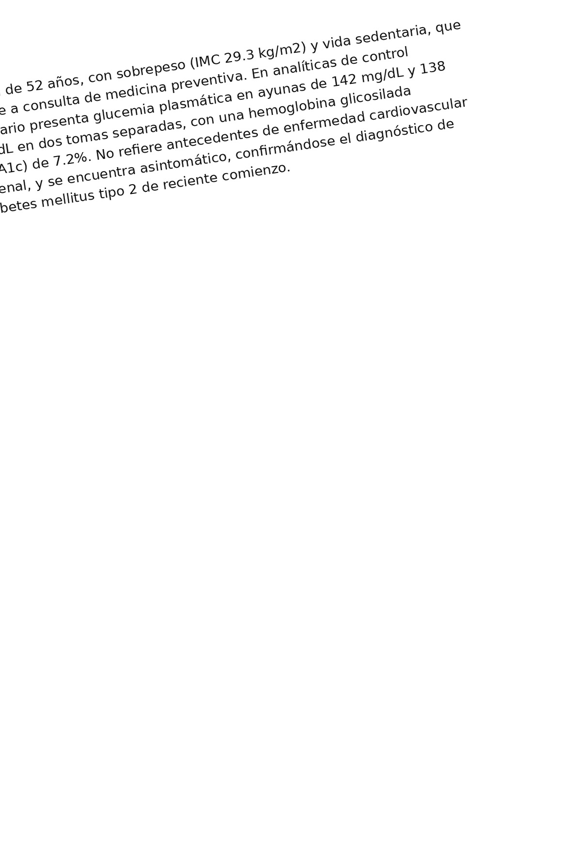

rotacion_recorte_severo | paginas: 1 | efectos: ['rotacion', 'recorte']


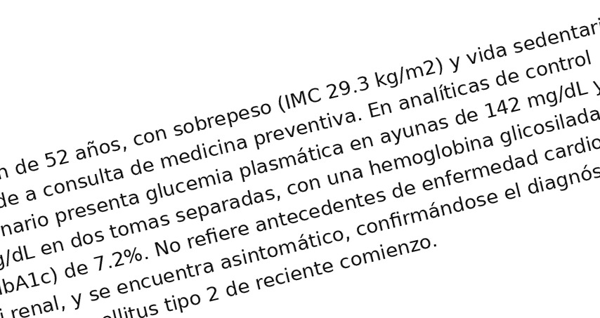

orientacion | paginas: 1 | efectos: ['orientacion']


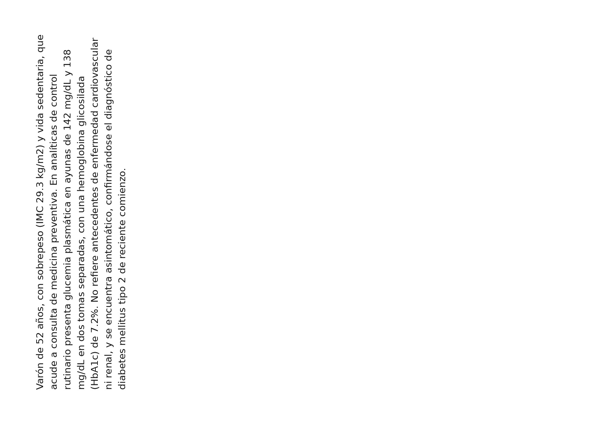

baja_resolucion_leve | paginas: 1 | efectos: ['resolucion']


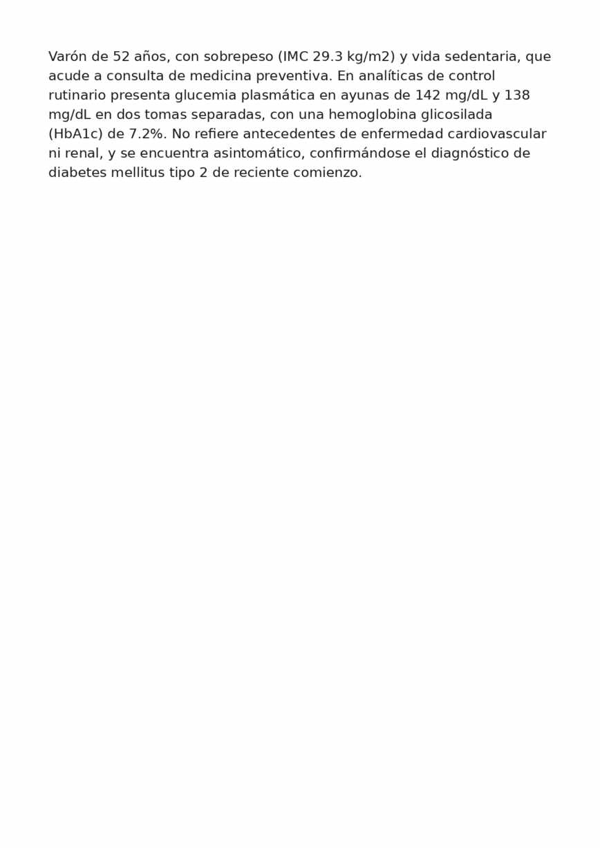

baja_resolucion_moderado | paginas: 1 | efectos: ['resolucion']


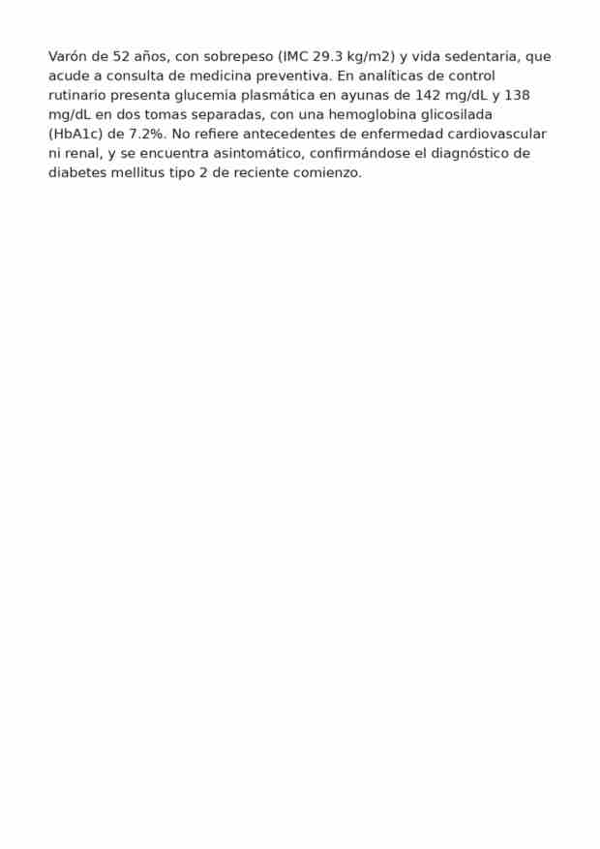

baja_resolucion_severo | paginas: 1 | efectos: ['desenfoque', 'resolucion']


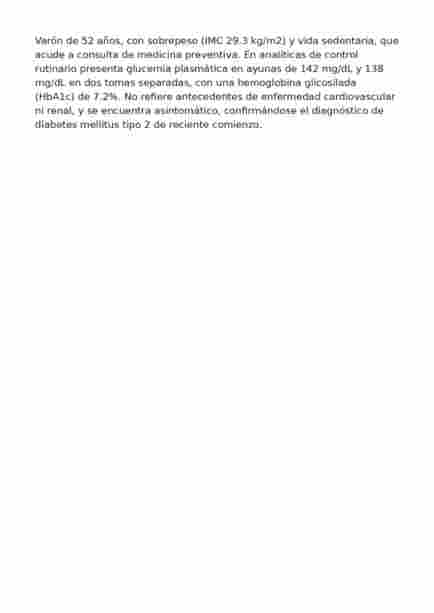

marcas_leve | paginas: 1 | efectos: ['perforaciones', 'resaltador']


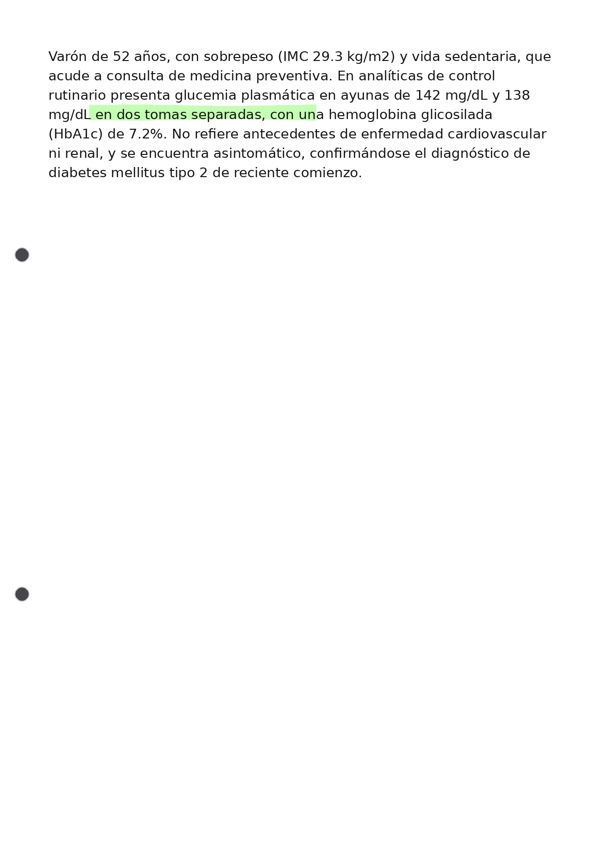

marcas_moderado | paginas: 1 | efectos: ['sello', 'firma', 'resaltador', 'notas_margen']


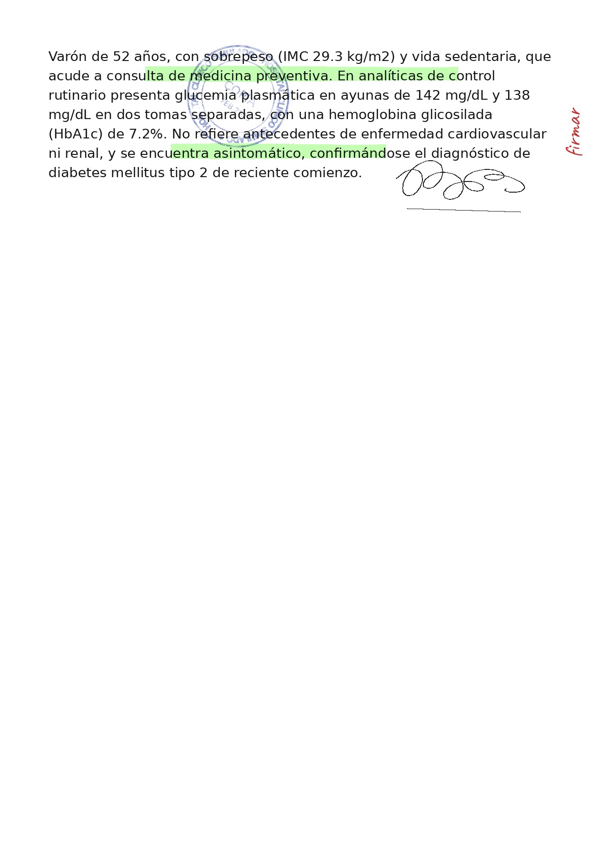

marcas_severo | paginas: 1 | efectos: ['mancha_cafe', 'sello', 'firma', 'resaltador', 'notas_margen']


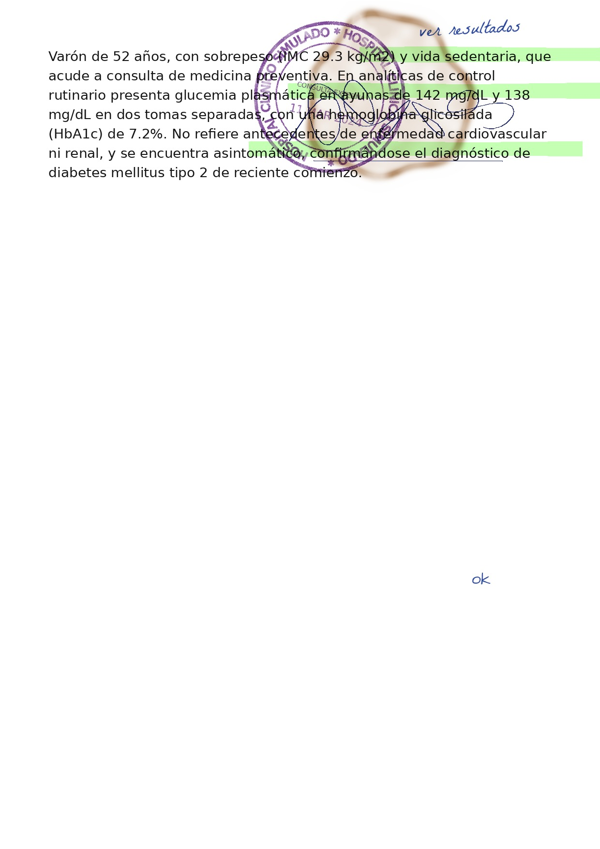

In [7]:
import json
from IPython.display import display
from PIL import Image

IMAGENES = PROJECT_ROOT / "M4/data/imagenes"
with open(IMAGENES / "manifest.json", encoding="utf-8") as f:
    manifest = json.load(f)

print(f"Documentos: {manifest['n_documentos']} | Imagenes: {manifest['n_imagenes']}")
print(f"{'nivel':28s} docs  pags  %palabras_ocultas  entidades no visibles")
for nivel, r in manifest["niveles"].items():
    e = r["entidades"]
    print(f"{nivel:28s} {r['documentos']:4d} {r['paginas']:5d} {r['pct_palabras_ocultas']:12.2f}"
          f"      {e['parcial'] + e['oculta']} de {e['total']}")

# Primera pagina del primer documento del subconjunto de barrido, en cada nivel
doc_id = manifest["subconjuntos"]["barrido"][0]
doc = next(d for d in manifest["documentos"] if d["doc_id"] == doc_id)
for nivel, info in doc["niveles"].items():
    pagina = info["paginas"][0]
    aplicados = [e["tipo"] for e in pagina["efectos"] if e["aplicado"]]
    print(nivel, "| paginas:", info["n_paginas"], "| efectos:", aplicados)
    img = Image.open(IMAGENES / pagina["archivo"])
    img.thumbnail((600, 850))
    display(img)